# Ham or Spam: SMS mesajlarında spam tespiti (NLP)

Amaç: Bir SMS'in **spam** (istenmeyen) mi **ham** (normal) mi olduğunu metninden tahmin etmek. İkinci bölümde aynı yöntem Yelp yorumlarında derin öğrenmeyle denenir.

## 1. Kütüphaneler

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import neattext as nfx
import joblib
import warnings
warnings.filterwarnings('ignore')

## 2. Veriyi okuma

In [2]:
df=pd.read_csv('spam.csv',encoding='iso-8859-1') # dosyada Türkçe dışı özel karakterler var

In [3]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df.shape

(5572, 5)

Son üç sütun neredeyse tamamen boş; atıp sütunlara anlaşılır isim veriyoruz.

In [5]:
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5572
Unnamed: 3    5572
Unnamed: 4    5572
dtype: int64

In [6]:
df=df.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1)
df.columns=['class','text']
df.head()

,class,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Keşifçi veri analizi

In [7]:
df['class'].value_counts()

class
ham     4825
spam     747
Name: count, dtype: int64

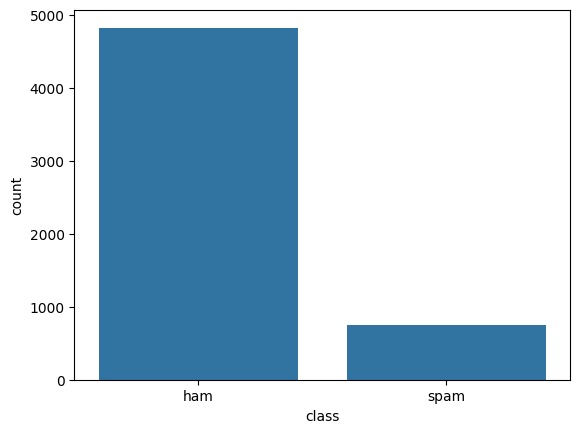

In [8]:
sns.countplot(x=df['class']);

In [9]:
df.duplicated().sum() # tekrar eden mesaj sayısı

np.int64(414)

In [10]:
df=df.drop_duplicates()
df.shape

(5158, 2)

In [11]:
df['uzunluk']=df['text'].str.len()
df.groupby('class')['uzunluk'].mean().round(1) # ortalama karakter sayısı

class
ham      70.6
spam    138.4
Name: uzunluk, dtype: float64

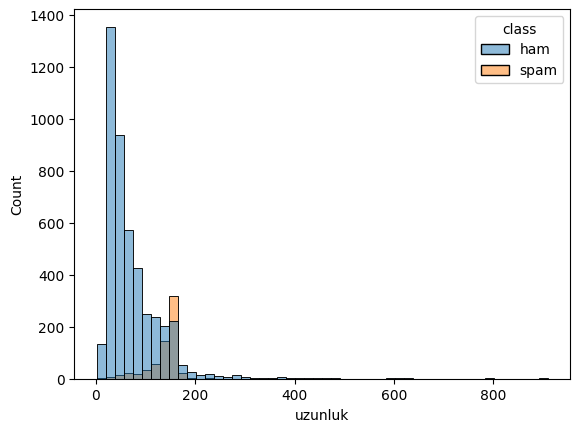

In [12]:
sns.histplot(x=df['uzunluk'],hue=df['class'],bins=50);

## 4. Metin temizleme

In [13]:
df['temiz']=df['text'].str.lower() # küçük harf
df['temiz']=df['temiz'].apply(nfx.remove_stopwords) # 'to', 'a', 'you' gibi gereksiz kelimeler
df['temiz']=df['temiz'].apply(nfx.remove_puncts) # noktalama
df['temiz']=df['temiz'].apply(nfx.remove_special_characters) # £, € gibi özel karakterler
df[['text','temiz']].head()

,text,temiz
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun early hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives


In [14]:
df[df['class']=='spam']['temiz'].str.split().explode().value_counts().head(10) # spam'lerde en sık 10 kelime

temiz
free      183
2         154
txt       124
u         122
ur        119
text      103
stop      103
mobile    101
claim      95
4          95
Name: count, dtype: int64

## 5. Eğitim ve test bölmesi

In [15]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df['temiz'],df['class'],test_size=.20,random_state=42,stratify=df['class'])

In [16]:
x_train.shape, x_test.shape

((4126,), (1032,))

## 6. Modeller (Pipeline: metin → sayı → model)

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [18]:
nb=Pipeline([('Vect',CountVectorizer()),('Classifier',MultinomialNB())]).fit(x_train,y_train)
rf=Pipeline([('Vect',CountVectorizer()),('Classifier',RandomForestClassifier(random_state=42))]).fit(x_train,y_train)
svm=Pipeline([('Tfidf',TfidfVectorizer()),('Classifier',SVC())]).fit(x_train,y_train) # Pipeline'a ham metin veriliyor

In [19]:
sonuc=pd.DataFrame({'Accuracy':[accuracy_score(y_test,nb.predict(x_test)),accuracy_score(y_test,rf.predict(x_test)),accuracy_score(y_test,svm.predict(x_test))],
                    'Spam F1':[f1_score(y_test,nb.predict(x_test),pos_label='spam'),f1_score(y_test,rf.predict(x_test),pos_label='spam'),f1_score(y_test,svm.predict(x_test),pos_label='spam')]},
                   index=['Naive Bayes','Random Forest','TF-IDF + SVC']).round(3)
sonuc.sort_values('Spam F1',ascending=False)

,Accuracy,Spam F1
Naive Bayes,0.983,0.927
TF-IDF + SVC,0.976,0.892
Random Forest,0.968,0.855


## 7. En iyi modelin ayrıntılı değerlendirmesi

In [20]:
model={'Naive Bayes':nb,'Random Forest':rf,'TF-IDF + SVC':svm}[sonuc['Spam F1'].idxmax()]
tahmin=model.predict(x_test)

In [21]:
pd.DataFrame(classification_report(y_test,tahmin,output_dict=True)).T.round(3)

,precision,recall,f1-score,support
ham,0.985,0.996,0.990,904.000
spam,0.966,0.891,0.927,128.000
accuracy,0.983,0.983,0.983,0.983
macro avg,0.975,0.943,0.958,1032.000
weighted avg,0.982,0.983,0.982,1032.000


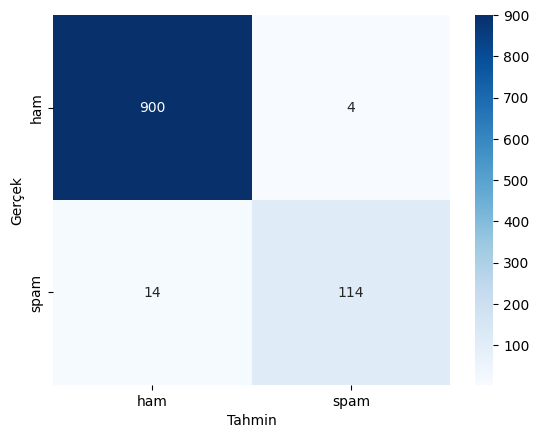

In [22]:
sns.heatmap(confusion_matrix(y_test,tahmin),annot=True,fmt='d',cmap='Blues',xticklabels=['ham','spam'],yticklabels=['ham','spam'])
plt.xlabel('Tahmin'); plt.ylabel('Gerçek');

## 8. Yeni mesajla deneme ve kaydetme

In [23]:
yeni=pd.Series(['Congratulations! You won a free iPhone, call now to claim','Are we still meeting for lunch tomorrow?'])
pd.DataFrame({'Mesaj':yeni,'Tahmin':model.predict(yeni.str.lower().apply(nfx.remove_stopwords).apply(nfx.remove_puncts).apply(nfx.remove_special_characters))})

,Mesaj,Tahmin
0,"Congratulations! You won a free iPhone, call n...",spam
1,Are we still meeting for lunch tomorrow?,ham


In [24]:
joblib.dump(model,'spam_model.pkl')

['spam_model.pkl']

---

# Bölüm 2: Yelp yorumları, derin öğrenme ile

Amaç: 1 yıldızlı (olumsuz) ve 5 yıldızlı (olumlu) yorumları ayırmak.

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
yelp=pd.read_csv('yelp.csv')
yelp['stars'].value_counts().sort_index()

stars
1     749
2     927
3    1461
4    3526
5    3337
Name: count, dtype: int64

In [26]:
yelp=yelp[(yelp['stars']==1)|(yelp['stars']==5)].reset_index(drop=True) # sadece en uç yorumlar
yelp['stars']=yelp['stars'].map({1:0,5:1}) # 0 olumsuz, 1 olumlu
yelp['stars'].value_counts()

stars
1    3337
0     749
Name: count, dtype: int64

In [27]:
yelp['text']=yelp['text'].str.lower().str.replace(r'[^\w\s]','',regex=True).str.replace(r'\d+','',regex=True)
xy_train,xy_test,yy_train,yy_test=train_test_split(yelp['text'],yelp['stars'],test_size=.20,random_state=42,stratify=yelp['stars'])

In [28]:
vect=CountVectorizer(stop_words='english',max_features=5000)
xv_train=vect.fit_transform(xy_train).toarray() # sözlük sadece eğitim verisinden öğrenilir
xv_test=vect.transform(xy_test).toarray()
xv_train.shape

(3268, 5000)

In [29]:
dl=Sequential([Input(shape=(5000,)),Dense(64,activation='relu'),Dropout(0.5),Dense(16,activation='relu'),Dense(1,activation='sigmoid')])
dl.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
history=dl.fit(xv_train,yy_train,validation_split=.10,epochs=5,batch_size=32,verbose=0)
pd.DataFrame(history.history).round(3)

,accuracy,loss,val_accuracy,val_loss
0,0.816,0.454,0.829,0.322
1,0.930,0.185,0.954,0.187
2,0.972,0.086,0.948,0.216
3,0.989,0.041,0.945,0.222
4,0.992,0.026,0.939,0.276


In [30]:
dl.evaluate(xv_test,yy_test,verbose=0)[1] # test accuracy

0.9339853525161743

In [31]:
nb_yelp=Pipeline([('Vect',CountVectorizer(stop_words='english')),('Classifier',MultinomialNB())]).fit(xy_train,yy_train)
accuracy_score(yy_test,nb_yelp.predict(xy_test)) # karşılaştırma: Naive Bayes

0.9242053789731052

## Sonuçların Değerlendirilmesi

| Model | Accuracy | Spam F1 |
|---|---|---|
| **Naive Bayes** | **0,983** | **0,927** |
| TF-IDF + SVC | 0,976 | 0,892 |
| Random Forest | 0,968 | 0,855 |

- Veride 414 tekrar eden mesaj vardı; silinince 5.158 mesaj kaldı. Mesajların %13'ü spam (veri dengesiz), bu yüzden accuracy'nin yanında spam F1'e bakıldı.
- Spam mesajlar normal mesajların yaklaşık iki katı uzun (ortalama 138 / 71 karakter); en sık kelimeleri "free", "txt", "mobile", "claim", "stop".
- En iyi model Naive Bayes: test verisindeki 128 spam'in 114'ünü yakaladı (recall 0,891), 904 normal mesajın sadece 4'ünü yanlışlıkla spam dedi.
- Yelp'te derin öğrenme modeli %93,4, Naive Bayes %92,4 doğruluk verdi; eğitim doğruluğu %99'a çıkarken doğrulama %94 civarında kaldı, yani 2-3 epoch'tan sonra ezberleme başlıyor.
- Kaydedilen dosya: `spam_model.pkl`.